# 02 — CDR on (MVP + FTR) vs CDR off

Single encounter, dpsi = 90 deg, dcpa = 0, perfect CNS (deterministic); 20, 40 and 60 kt.

20kt: MVP() + FTR(), margin 1.05 | min sep CDR off 0.0 m, CDR on 150.9 m | LoS False | speed 10.29-10.92 m/s (own), 9.69-10.29 m/s (intr) | ended 421 s


40kt: MVP() + FTR(), margin 1.05 | min sep CDR off 0.0 m, CDR on 151.9 m | LoS False | speed 20.58-21.35 m/s (own), 19.83-20.58 m/s (intr) | ended 416 s


60kt: MVP() + FTR(), margin 1.05 | min sep CDR off 0.0 m, CDR on 156.4 m | LoS False | speed 21.87-30.87 m/s (own), 20.67-30.87 m/s (intr) | ended 448 s


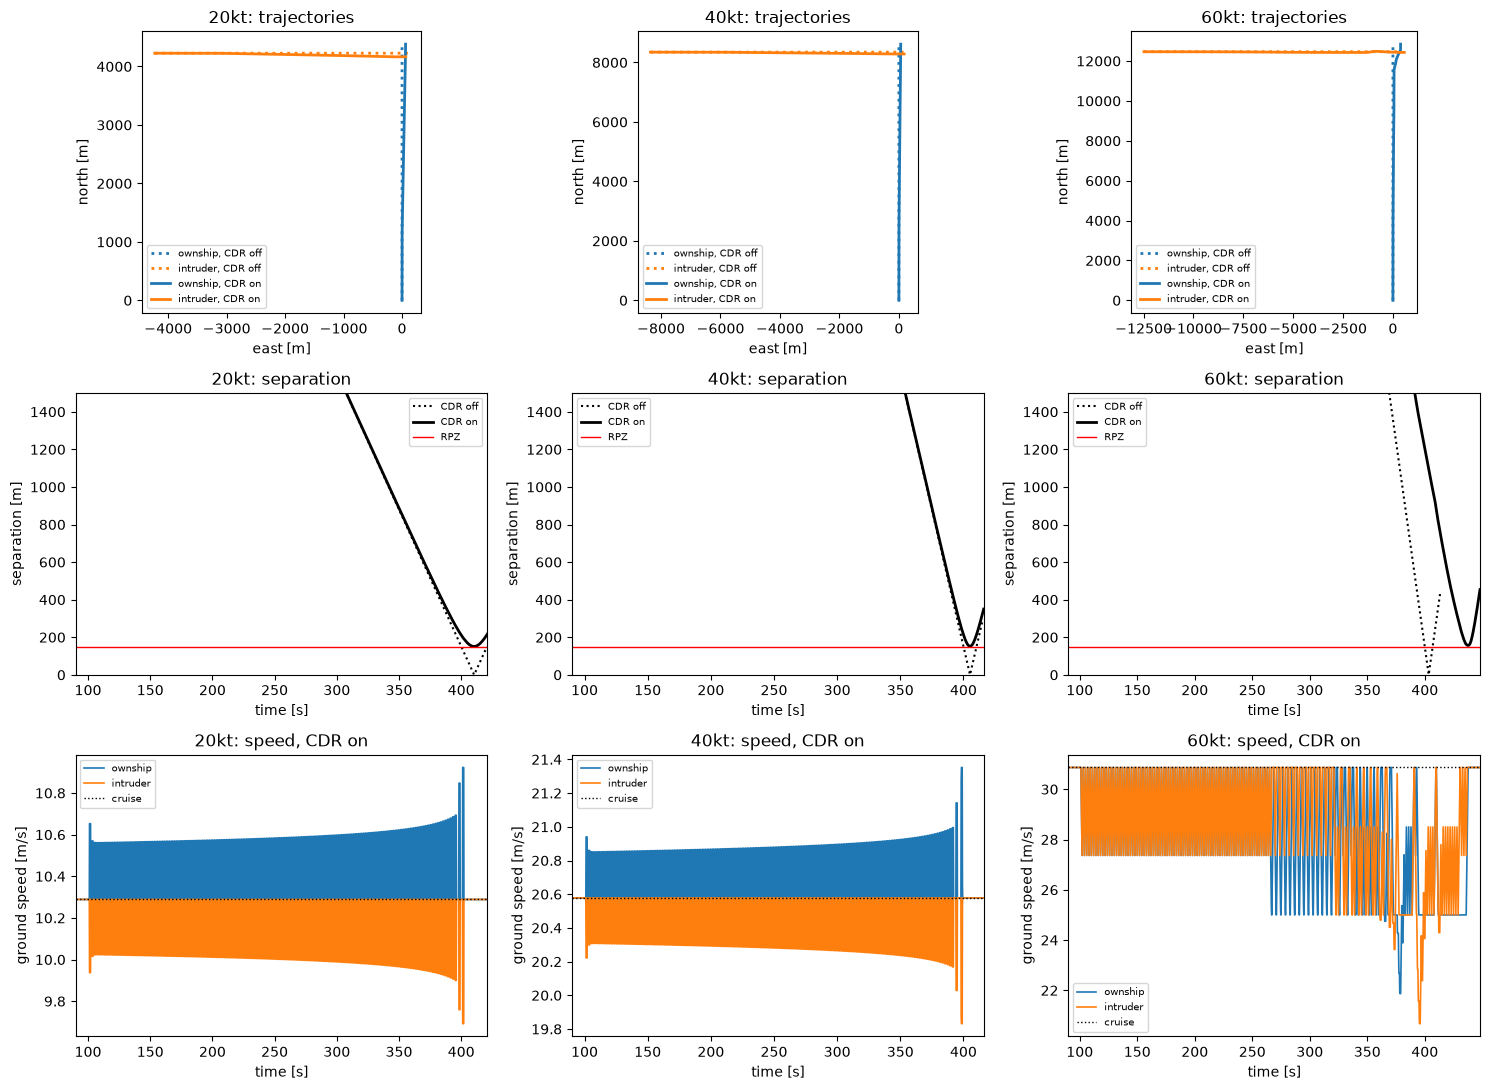

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace

from blueskycdarr.episode import run_episode
from blueskycdarr.geo import enu_offset
from blueskycdarr.recovery import FTR
from blueskycdarr.rng import child
from sanity import campaign_setup, config, fly, point

DPSI = 90.0
RPZ = config.FIXED["rpz"]
PERFECT_CNS = {"p_reception": 1.0, "max_range_m": None, "pos_ci95": 0.0, "vel_ci95": 0.0}  # deterministic

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for col, (cls, v) in enumerate(config.SPEED_CLASSES.items()):
    cfg, models, _, _, root = campaign_setup(point(cls, DPSI, cns=PERFECT_CNS), dcpa=0.0)
    models = replace(models, recovery=FTR(), scenario=replace(models.scenario, pairs=(1, 1)))

    off = fly(cfg, models, seconds=cfg.simulation.t_max, stop_after_cpa=cfg.simulation.done_timeout)  # CDR off

    log = []                                                                                     # CDR on
    res = run_episode(models.scenario, models.aircraft, cfg, child(root, 0),
                      models.recovery, models.resolver, models.noise,
                      recorder=lambda t, truth, d: log.append((t, truth.lat.copy(), truth.lon.copy(), truth.gs.copy(), d[0])))
    on = {"t": np.array([r[0] for r in log]), "lat": np.array([r[1] for r in log]),
          "lon": np.array([r[2] for r in log]), "gs": np.array([r[3] for r in log]),
          "dist": np.array([r[4] for r in log])}

    print(f"{cls}: {models.resolver} + {models.recovery}, margin {cfg.conflict.resolution_margin} | "
          f"min sep CDR off {off['dist'].min():.1f} m, CDR on {res.min_sep[0]:.1f} m | LoS {res.n_los == 1} | "
          f"speed {on['gs'][:, 0].min():.2f}-{on['gs'][:, 0].max():.2f} m/s (own), "
          f"{on['gs'][:, 1].min():.2f}-{on['gs'][:, 1].max():.2f} m/s (intr) | ended {res.t_end:.0f} s")

    lat0, lon0 = off["lat"][0, 0], off["lon"][0, 0]
    ax = axes[0, col]
    for f, ls, lab in ((off, ":", "CDR off"), (on, "-", "CDR on")):
        e, n = enu_offset(lat0, lon0, f["lat"], f["lon"])
        ax.plot(e[:, 0], n[:, 0], "C0", ls=ls, lw=2, label=f"ownship, {lab}")
        ax.plot(e[:, 1], n[:, 1], "C1", ls=ls, lw=2, label=f"intruder, {lab}")
    ax.set_aspect("equal"); ax.set_xlabel("east [m]"); ax.set_ylabel("north [m]")
    ax.set_title(f"{cls}: trajectories"); ax.legend(fontsize=7)

    t_end = max(off["t"][-1], on["t"][-1])
    ax = axes[1, col]
    ax.plot(off["t"], off["dist"][:, 0], "k:", lw=1.5, label="CDR off")
    ax.plot(on["t"], on["dist"], "k-", lw=2, label="CDR on")
    ax.axhline(RPZ, color="r", lw=1, label="RPZ")
    ax.set_ylim(0, 1500); ax.set_xlim(90, t_end)
    ax.set_xlabel("time [s]"); ax.set_ylabel("separation [m]"); ax.set_title(f"{cls}: separation")
    ax.legend(fontsize=7)

    ax = axes[2, col]
    ax.plot(on["t"], on["gs"][:, 0], "C0", lw=1.2, label="ownship")
    ax.plot(on["t"], on["gs"][:, 1], "C1", lw=1.2, label="intruder")
    ax.axhline(v, color="k", lw=1, ls=":", label="cruise")
    ax.set_xlim(90, t_end)
    ax.set_xlabel("time [s]"); ax.set_ylabel("ground speed [m/s]"); ax.set_title(f"{cls}: speed, CDR on")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()